<a href="https://colab.research.google.com/github/Oli-via123/Satellite-Orbit-Explorer/blob/main/Satellite_Orbit_Explorer_%7C_Chidinma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Satellite Orbit Explorer

## Space Career Week 2026

### Project Overview

This project explores satellite orbital mechanics using Python. It involves retrieving satellite orbital data, analysing satellite movement, calculating orbital parameters, and creating visualizations.


```markdown
# Satellite Orbit Explorer · built during Space Career Week 2026 · GNSS Academy

Welcome! In this Python tutorial, we will explore satellite orbital mechanics step-by-step using an educational two-body Keplerian model. Here is our 8-stage roadmap:

1. **Setup**: Import libraries, define physical constants, and establish working directories.
2. **Load GP JSON**: Load General Perturbation (GP) satellite data from JSON format.
3. **Parse Elements**: Extract Keplerian orbital elements from SGP4 mean elements.
4. **Time Window**: Set up simulation start times and coordinate frames.
5. **Propagate**: Calculate satellite positions over time using the two-body Kepler model.
6. **Orbit Summary**: Compute orbital characteristics (e.g., period, apogee, perigee).
7. **Plots**: Generate 2D projections of satellite trajectories.
8. **KML and Report**: Export visual data to Keyhole Markup Language (KML) and summarize findings.
```

In [23]:
# Stage 1: Setup
import json
import math
import time
import zipfile
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import requests

# Standard Constants (Keplerian physics with a spherical, rotating Earth)
MU_EARTH_KM3_S2 = 398600.4418  # Gravitational parameter of Earth (km^3 / s^2)
EARTH_RADIUS_KM = 6378.137      # Mean equatorial radius of Earth (km)

# Project Directories
BASE_DIR = Path('/content/satellite_orbits')
IN_DIR = BASE_DIR / 'input'
OUT_DIR = BASE_DIR / 'output'

# Ensure working directories exist
IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Simulation Configuration
STEP_SECONDS = 5
DURATION_HOURS = 24
LIVE_GROUP = 'GALILEO'  # Reserved for optional future extension

# Display configuration settings to verify success
print("=== Stage 1 Setup Successful ===")
print(f"Input Directory:  {IN_DIR}")
print(f"Output Directory: {OUT_DIR}")
print(f"Simulation Step:  {STEP_SECONDS} seconds")
print(f"Duration:         {DURATION_HOURS} hours")
print(f"Earth MU:         {MU_EARTH_KM3_S2} km^3/s^2")
print(f"Earth Radius:     {EARTH_RADIUS_KM} km")

=== Stage 1 Setup Successful ===
Input Directory:  /content/satellite_orbits/input
Output Directory: /content/satellite_orbits/output
Simulation Step:  5 seconds
Duration:         24 hours
Earth MU:         398600.4418 km^3/s^2
Earth Radius:     6378.137 km


```markdown
## Stage 2: Load GP JSON Data

Unlike the legacy Two-Line Element (TLE) format which relies on rigid, column-based plain text files prone to parsing offsets, the Orbit Mean-Elements Message (OMM) JSON format provides named key-value fields and standardized ISO date-time strings. Additionally, OMM JSON easily accommodates six-digit NORAD catalog numbers without truncation, making data ingestion robust, self-documenting, and simpler to parse natively in Python.
```

In [24]:
# Helper function to extract inputs
def extract_inputs():
    """
    Checks for existing required files in IN_DIR. If missing, prompts the user
    to upload orbit_workshop_inputs.zip to /content, waits for it, and extracts
    the three target files into IN_DIR.
    """
    required = ['orbital_elements.json', 'data_manifest.json', 'world_map.txt']
    all_exist = all((IN_DIR / f).is_file() for f in required)
    if all_exist:
        print("All required input files already exist in the input directory.")
        return

    print("----------------------------------------------------------------------")
    print("ACTION REQUIRED: Please drag 'orbit_workshop_inputs.zip' (or matching")
    print("orbit_workshop_inputs*.zip) into the Colab Files panel on the left.")
    print("----------------------------------------------------------------------")

    content_dir = Path('/content')
    zip_path = None
    timeout = time.time() + 900  # 15 minutes timeout

    while True:
        if time.time() > timeout:
            raise TimeoutError("Timed out waiting for 'orbit_workshop_inputs.zip' to be uploaded.")

        # Search for a matching zip file in /content
        for file in content_dir.glob('orbit_workshop_inputs*.zip'):
            if zipfile.is_zipfile(file):
                zip_path = file
                break

        if zip_path:
            break

        time.sleep(2)

    print(f"Found valid zip file: {zip_path.name}. Extracting required inputs...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        for name in required:
            # Extract directly to the target input directory
            data = zip_ref.read(name)
            (IN_DIR / name).write_bytes(data)
            print(f"  - Extracted {name} to {IN_DIR}")

# Helper function to read and validate the GP JSON data
def read_gp_json(path):
    """
    Loads a JSON list containing GP records and validates that all necessary
    orbital components are present.
    """
    if not path.exists():
        raise FileNotFoundError(f"Target JSON file not found at: {path}")

    with open(path, 'r') as f:
        records = json.load(f)

    required_fields = [
        'OBJECT_NAME', 'NORAD_CAT_ID', 'EPOCH', 'MEAN_MOTION',
        'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE',
        'ARG_OF_PERICENTER', 'MEAN_ANOMALY'
    ]

    for idx, rec in enumerate(records):
        for field in required_fields:
            if field not in rec:
                obj_name = rec.get('OBJECT_NAME', f'Index {idx}')
                raise ValueError(f"Record '{obj_name}' is missing the required field: {field}")

    return records

In [25]:
# Run the extraction and load stage data
extract_inputs()

# Load and display manifest metadata
with open(IN_DIR / 'data_manifest.json', 'r') as f:
    data_manifest = json.load(f)

source_note = f"Data sourced from Space-Track / CelesTrak. Retrieved UTC: {data_manifest['retrieved_utc']}"
print(source_note)
print("-" * 80)

# Read and validate GP satellite records
sats = read_gp_json(IN_DIR / 'orbital_elements.json')
print(f"Successfully loaded {len(sats)} satellite records:")
for sat in sats:
    print(f"Name: {sat['OBJECT_NAME']:<20} ID: {sat['NORAD_CAT_ID']:<8} Epoch: {sat['EPOCH']}")

All required input files already exist in the input directory.
Data sourced from Space-Track / CelesTrak. Retrieved UTC: 2026-11-10T16:30:32Z
--------------------------------------------------------------------------------
Successfully loaded 4 satellite records:
Name: PULSAR-0             ID: 64541    Epoch: 2026-11-10T04:10:34.900320
Name: GSAT0225 (GALILEO 29) ID: 59598    Epoch: 2026-11-09T08:30:06.579648
Name: SES-5                ID: 38652    Epoch: 2026-11-10T04:02:09.139776
Name: QZS-2 (MICHIBIKI-2)  ID: 42738    Epoch: 2026-10-17T15:21:52.982784


```markdown
## Stage 3: Parse GP Records to Keplerian Elements

The General Perturbation (GP) parameters from CelesTrak are standard SGP4 mean elements. Using them directly in a classical two-body Keplerian model is an educational approximation, as SGP4 elements are formulated to account for secular and periodic perturbations (such as Earth's oblateness $J_2$ and atmospheric drag) which our simplified model ignores.

### GP Field to Keplerian Element Mapping

| GP JSON Field | Description | Symbol | Model Unit | Conversion Applied |
| :--- | :--- | :---: | :---: | :--- |
| `MEAN_MOTION` | Mean Motion ($n$) | $n$ | rad/s | $2 \pi \times \text{MEAN}\_\text{MOTION} / 86400$ |
| — | Semi-major axis ($a$) | $a$ | km | Kepler's Third Law: $a = \left(\frac{\mu_{Earth}}{n^2}\right)^{1/3}$ |
| `ECCENTRICITY` | Eccentricity | $e$ | unitless | Already decimal fraction (no conversion) |
| `INCLINATION` | Inclination | $i$ | rad | $\text{INCLINATION} \times \frac{\pi}{180}$ |
| `RA_OF_ASC_NODE`| Right Ascension of Ascending Node | $\Omega$ | rad | $\text{RA}\_\text{OF}\_\text{ASC}\_\text{NODE} \times \frac{\pi}{180}$ |
| `ARG_OF_PERICENTER`| Argument of Perigee | $\omega$ | rad | $\text{ARG}\_\text{OF}\_\text{PERICENTER} \times \frac{\pi}{180}$ |
| `MEAN_ANOMALY` | Mean Anomaly at Epoch | $M_0$ | rad | $\text{MEAN}\_\text{ANOMALY} \times \frac{\pi}{180}$ |
| `EPOCH` | Reference Epoch | $t_0$ | datetime | UTC-aware Python datetime |
```

In [27]:
# Helper function to parse Epoch strings
def parse_gp_epoch(text):
    """
    Parses ISO 8601 UTC epoch strings. Strips any trailing 'Z' and enforces UTC tzinfo.
    """
    clean_text = text.rstrip('Z')
    return datetime.fromisoformat(clean_text).replace(tzinfo=timezone.utc)

# Helper function to convert GP JSON records to model elements
def parse_gp_elements(rec):
    """
    Converts an OMM JSON GP record into standard Keplerian model elements in model units (km, rad, rad/s).
    """
    name = rec['OBJECT_NAME']
    norad_id = int(rec['NORAD_CAT_ID'])
    label = f"{name} [{norad_id}]"
    epoch = parse_gp_epoch(rec['EPOCH'])

    # Convert Mean Motion from rev/day to rad/s
    n_rev_day = rec['MEAN_MOTION']
    n_rad_s = (2.0 * math.pi * n_rev_day) / 86400.0

    # Calculate Semi-major axis 'a' in km using Kepler's Third Law
    a_km = (MU_EARTH_KM3_S2 / (n_rad_s ** 2)) ** (1.0 / 3.0)

    # Convert Keplerian angles from degrees to radians
    e = float(rec['ECCENTRICITY'])
    i_rad = math.radians(rec['INCLINATION'])
    raan_rad = math.radians(rec['RA_OF_ASC_NODE'])
    argp_rad = math.radians(rec['ARG_OF_PERICENTER'])
    M0_rad = math.radians(rec['MEAN_ANOMALY'])

    return {
        'name': name,
        'norad_id': norad_id,
        'label': label,
        'epoch': epoch,
        'n_rad_s': n_rad_s,
        'a_km': a_km,
        'e': e,
        'i_rad': i_rad,
        'raan_rad': raan_rad,
        'argp_rad': argp_rad,
        'M0_rad': M0_rad
    }

# Helper function to build a formatted printable text table of elements
def elements_table(elements_list):
    """
    Formats parsed Keplerian elements into a printable text table.
    """
    lines = []
    header = f"{'Satellite Name':<20} | {'NORAD':<6} | {'Epoch (UTC)':<26} | {'a (km)':<9} | {'e':<8} | {'i (deg)':<7} | {'RAAN (deg)':<10} | {'ARGP (deg)':<10} | {'M0 (deg)':<8}"
    separator = "-" * len(header)
    lines.append(header)
    lines.append(separator)

    for el in elements_list:
        epoch_str = el['epoch'].strftime('%Y-%m-%d %H:%M:%S.%f')[:-3]
        line = (f"{el['name']:<20} | "
                f"{el['norad_id']:<6} | "
                f"{epoch_str:<26} | "
                f"{el['a_km']:9.2f} | "
                f"{el['e']:8.6f} | "
                f"{math.degrees(el['i_rad']):7.2f} | "
                f"{math.degrees(el['raan_rad']):10.2f} | "
                f"{math.degrees(el['argp_rad']):10.2f} | "
                f"{math.degrees(el['M0_rad']):8.2f}")
        lines.append(line)

    return lines

In [28]:
# Validate requirements and execute parsing
if 'sats' not in globals() or not sats:
    raise NameError("Missing GP satellite records 'sats' from previous stage. Ensure Stage 2 ran successfully.")

# Parse all GP records
elements = [parse_gp_elements(s) for s in sats]

# Format and display the elements table
table_lines = elements_table(elements)
for line in table_lines:
    print(line)

Satellite Name       | NORAD  | Epoch (UTC)                | a (km)    | e        | i (deg) | RAAN (deg) | ARGP (deg) | M0 (deg)
--------------------------------------------------------------------------------------------------------------------------------
GSAT0101 (GALILEO-PFM) | 37846  | 2026-11-12 20:10:58.838    |  29600.11 | 0.000219 |   56.93 |     337.72 |     310.54 |    49.48
GSAT0102 (GALILEO-FM2) | 37847  | 2026-11-13 22:26:02.235    |  29600.08 | 0.000419 |   56.93 |     337.69 |     308.89 |    48.18
GSAT0103 (GALILEO-FM3) | 38857  | 2026-11-13 11:15:01.175    |  29600.39 | 0.000179 |   55.91 |      97.45 |     280.69 |    79.26
GSAT0201 (GALILEO 5) | 40128  | 2026-11-13 17:10:55.794    |  27977.47 | 0.169458 |   48.72 |     267.29 |     185.10 |   172.96


```markdown
## Stage 4: Common UTC Time Window and Epoch Offsets

Having a unified UTC time grid is essential for synchronizing and comparing multiple satellite trajectories. Because each satellite record is analytical and propagated directly from its own distinct reference epoch, propagation errors accumulate and grow over time due to neglected perturbations. Comparing the simulation start time to each satellite's epoch helps us identify stale data; for example, our QZS-2 record dates back to October 17, 2026, which is heavily stale and will exhibit significantly larger approximation errors compared to newer records.
```

In [29]:
# Validate dependencies from earlier stages
if 'elements' not in globals() or not elements:
    raise NameError("Missing 'elements' from Stage 3. Ensure Stage 3 was run successfully.")

# 1. Determine the common UTC time window
# The start time is the newest epoch in our elements, floored to UTC midnight
newest_epoch = max(el['epoch'] for el in elements)
start = newest_epoch.replace(hour=0, minute=0, second=0, microsecond=0)
end = start + timedelta(hours=DURATION_HOURS)

# Compute total points on the grid including both ends
total_seconds = int((end - start).total_seconds())
n_points = (total_seconds // STEP_SECONDS) + 1
times = [start + timedelta(seconds=i * STEP_SECONDS) for i in range(n_points)]

# Print time window details
print("=== Simulation Time Window ===")
print(f"Start (UTC):  {start}")
print(f"End (UTC):    {end}")
print(f"Grid Points:  {n_points} steps (step size = {STEP_SECONDS}s)\n")

# 2. Analyze offset ages and flag stale records
print("=== Satellite Epoch Age Analysis ===")
for el in elements:
    offset = start - el['epoch']
    offset_days = offset.total_seconds() / 86400.0

    status_flag = ""
    if offset_days > 7.0:
        status_flag = " [STALE RECORD]"
    elif offset_days < 0:
        status_flag = " [FUTURE EPOCH relative to start]"

    print(f"Satellite: {el['label']:<30} | Offset: {offset_days:8.4f} days{status_flag}")

=== Simulation Time Window ===
Start (UTC):  2026-11-13 00:00:00+00:00
End (UTC):    2026-11-14 00:00:00+00:00
Grid Points:  17281 steps (step size = 5s)

=== Satellite Epoch Age Analysis ===
Satellite: GSAT0101 (GALILEO-PFM) [37846] | Offset:   0.1590 days
Satellite: GSAT0102 (GALILEO-FM2) [37847] | Offset:  -0.9347 days [FUTURE EPOCH relative to start]
Satellite: GSAT0103 (GALILEO-FM3) [38857] | Offset:  -0.4688 days [FUTURE EPOCH relative to start]
Satellite: GSAT0201 (GALILEO 5) [40128]   | Offset:  -0.7159 days [FUTURE EPOCH relative to start]


```markdown
## Stage 5: Two-Body Keplerian Orbit Propagation

In this stage, we implement the physical equations of orbital motion:
1. **Kepler's Equation Solver**: Relates mean anomaly ($M$) to eccentric anomaly ($E$) via $M = E - e\sin(E)$, solved numerically with the Newton-Raphson method.
2. **Greenwich Mean Sidereal Time (GMST)**: Calculates the Earth's rotational angle using the IAU-1982 formulation relative to the J2000 epoch.
3. **3D Keplerian State & Rotation**: Computes the satellite's position in its orbital plane, projects it into the 3D Geocentric Equatorial Inertial (GEI) frame, rotates it into the Earth-Centered Earth-Fixed (ECEF) rotating frame using GMST, and extracts latitude, longitude, altitude, and speed.
```

In [30]:
# Validate dependencies
if 'elements' not in globals() or 'times' not in globals():
    raise NameError("Missing variables from previous stages. Ensure Stages 1-4 ran successfully.")

def solve_kepler(M, e):
    """
    Solves Kepler's Equation: M = E - e * sin(E) using Newton-Raphson iteration.
    """
    # Handle initial guess as specified
    E = math.pi if e > 0.8 else M
    tol = 1e-12
    for _ in range(50):
        f = E - e * math.sin(E) - M
        df = 1.0 - e * math.cos(E)
        delta = f / df
        E -= delta
        if abs(delta) < tol:
            return E
    raise RuntimeError(f"Kepler solver failed to converge. M={M}, e={e}")

def gmst_rad(t):
    """
    Calculates Greenwich Mean Sidereal Time (GMST) in radians using IAU-1982 formula.
    """
    # J2000.0 epoch is January 1, 2000 at 12:00:00 UTC
    j2000 = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
    d = (t - j2000).total_seconds() / 86400.0
    T = d / 36525.0

    # IAU-1982 GMST formula in degrees
    theta_deg = 280.46061837 + 360.98564736629 * d + 0.000387933 * T**2 - (T**3) / 38710000.0
    return math.radians(theta_deg % 360.0)

def propagate(el, times_list):
    """
    Propagates a satellite's orbit over a list of UTC datetimes using two-body Kepler mechanics.
    """
    a = el['a_km']
    e = el['e']
    i = el['i_rad']
    raan = el['raan_rad']
    argp = el['argp_rad']
    M0 = el['M0_rad']
    n = el['n_rad_s']
    epoch = el['epoch']

    points = []
    for t in times_list:
        # 1) Mean Anomaly calculation with time offset from epoch
        dt = (t - epoch).total_seconds()
        M = (M0 + n * dt) % (2.0 * math.pi)

        # 2) Solve Kepler's equation for Eccentric Anomaly
        E = solve_kepler(M, e)

        # 3) Radial distance, True Anomaly, and Argument of Latitude
        r = a * (1.0 - e * math.cos(E))
        nu = math.atan2(math.sqrt(1.0 - e**2) * math.sin(E), math.cos(E) - e)
        u = argp + nu

        # 4) Position in Inertial coordinates (GEI Frame)
        x = r * (math.cos(raan) * math.cos(u) - math.sin(raan) * math.sin(u) * math.cos(i))
        y = r * (math.sin(raan) * math.cos(u) + math.cos(raan) * math.sin(u) * math.cos(i))
        z = r * (math.sin(u) * math.sin(i))

        # 5) Rotate to Earth-Fixed frame (ECEF) using Greenwich Sidereal Time
        theta = gmst_rad(t)
        xp = math.cos(theta) * x + math.sin(theta) * y
        yp = -math.sin(theta) * x + math.cos(theta) * y

        # 6) Spherical geocentric lat, lon, and altitude
        lat = math.degrees(math.atan2(z, math.hypot(xp, yp)))
        lon = math.degrees(math.atan2(yp, xp))
        # Normalize longitude to range [-180, 180]
        lon = (lon + 180.0) % 360.0 - 180.0
        alt = r - EARTH_RADIUS_KM

        # 7) Vis-Viva orbital velocity magnitude
        speed = math.sqrt(MU_EARTH_KM3_S2 * (2.0 / r - 1.0 / a))

        points.append({
            'time': t,
            'lat_deg': lat,
            'lon_deg': lon,
            'alt_km': alt,
            'speed_km_s': speed
        })
    return points

In [31]:
# --- Validation and Assertions ---

# 1. GMST validation near J2000 (12:00:00 on Jan 1, 2000)
j2000_t = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
gmst_j2000_deg = math.degrees(gmst_rad(j2000_t))
assert abs(gmst_j2000_deg - 280.4606) < 0.01, f"GMST at J2000 failed: {gmst_j2000_deg:.4f}"
print("✓ Assertion passed: GMST at J2000 matches Meeus Eq 12.4 (~280.46 deg)")

# 2. Kepler solver validation
for test_M in [0.1, 1.5, 3.0]:
    for test_e in [0.01, 0.1, 0.5]:
        test_E = solve_kepler(test_M, test_e)
        residual = abs(test_E - test_e * math.sin(test_E) - test_M)
        assert residual < 1e-10, f"Kepler residual exceeded: {residual}"
print("✓ Assertion passed: Kepler residuals are below 1e-10")

# --- Propagate All Tracks ---
tracks = [propagate(el, times) for el in elements]

# 3. Dynamic check on SES-5 longitude bounds (Geostationary, ~5 deg East)
ses5_idx = next((idx for idx, el in enumerate(elements) if el['norad_id'] == 38652), None)
if ses5_idx is not None:
    ses5_lons = [pt['lon_deg'] for pt in tracks[ses5_idx]]
    min_lon, max_lon = min(ses5_lons), max(ses5_lons)
    print(f"SES-5 (Geostationary) Longitude Range: {min_lon:.4f}° to {max_lon:.4f}°")
    assert all(4.0 <= lon <= 6.0 for lon in ses5_lons), f"SES-5 longitude drifted outside boundaries: {min_lon:.3f} to {max_lon:.3f}"
    print("✓ Assertion passed: SES-5 geostationary longitude stays within [4, 6] degrees East")

# --- Display Propagation Highlights ---
print("\n=== Propagation Sample Points ===")
for idx, el in enumerate(elements):
    track = tracks[idx]
    samples = [track[0], track[len(track) // 2], track[-1]]
    print(f"\nSatellite: {el['label']}")
    for label, pt in zip(["Start ", "Middle", "End   "], samples):
        print(f"  {label} ({pt['time'].strftime('%H:%M:%S')} UTC) | Lat: {pt['lat_deg']:7.2f}° | Lon: {pt['lon_deg']:7.2f}° | Alt: {pt['alt_km']:8.2f} km | Speed: {pt['speed_km_s']:5.2f} km/s")

✓ Assertion passed: GMST at J2000 matches Meeus Eq 12.4 (~280.46 deg)
✓ Assertion passed: Kepler residuals are below 1e-10

=== Propagation Sample Points ===

Satellite: GSAT0101 (GALILEO-PFM) [37846]
  Start  (00:00:00 UTC) | Lat:   56.16° | Lon:   29.41° | Alt: 23227.43 km | Speed:  3.67 km/s
  Middle (12:00:00 UTC) | Lat:   35.98° | Lon:  133.31° | Alt: 23222.42 km | Speed:  3.67 km/s
  End    (00:00:00 UTC) | Lat:   -7.24° | Lon:  -80.13° | Alt: 23217.05 km | Speed:  3.67 km/s

Satellite: GSAT0102 (GALILEO-FM2) [37847]
  Start  (00:00:00 UTC) | Lat:   29.98° | Lon:   83.51° | Alt: 23233.94 km | Speed:  3.67 km/s
  Middle (12:00:00 UTC) | Lat:   56.93° | Lon: -164.39° | Alt: 23231.63 km | Speed:  3.67 km/s
  End    (00:00:00 UTC) | Lat:   30.42° | Lon:  -52.95° | Alt: 23221.56 km | Speed:  3.67 km/s

Satellite: GSAT0103 (GALILEO-FM3) [38857]
  Start  (00:00:00 UTC) | Lat:   52.08° | Lon:  105.64° | Alt: 23226.91 km | Speed:  3.67 km/s
  Middle (12:00:00 UTC) | Lat:   15.76° | Lon: -

```markdown
## Stage 6: Orbit Summary Analysis

Based on our calculations, we can interpret the orbital characteristics as follows:
- **PULSAR-0**: Has a short period of about 1.58 hours and an inclination of ~97.5° (greater than 90°), which indicates a retrograde, near-polar, sun-synchronous Low Earth Orbit (LEO).
- **GSAT0225 (Galileo 29)**: Possesses a semi-synchronous Medium Earth Orbit (MEO) with a period of about 14.08 hours.
- **SES-5 & QZS-2**: Both have orbital periods of approximately 23.93 hours, matching one Earth sidereal day.
- **QZS-2**: Unlike the geostationary SES-5 (inclination near 0°), QZS-2 features an eccentricity of ~0.075 and an inclination of ~39.2°. This describes an Inclined Geosynchronous Orbit (IGSO) designed to trace a figure-eight ground track over East Asia and Oceania.
```

In [32]:
# Validate dependencies from previous stages
if 'elements' not in globals() or 'tracks' not in globals():
    raise NameError("Missing variables 'elements' or 'tracks' from earlier stages. Ensure Stages 1-5 ran successfully.")

def orbit_summary(el, pts):
    """
    Computes summary metrics for a satellite based on Keplerian elements and simulated track points.
    """
    a = el['a_km']
    e = el['e']
    n = el['n_rad_s']

    # Calculate period in hours, perigee/apogee altitudes in km
    period_h = (2.0 * math.pi) / n / 3600.0
    perigee_km = a * (1.0 - e) - EARTH_RADIUS_KM
    apogee_km = a * (1.0 + e) - EARTH_RADIUS_KM
    i_deg = math.degrees(el['i_rad'])

    # Extract minimum and maximum speeds from simulated trajectory points
    speeds = [pt['speed_km_s'] for pt in pts]
    min_speed = min(speeds)
    max_speed = max(speeds)

    return {
        'name': el['name'],
        'norad_id': el['norad_id'],
        'period_h': period_h,
        'perigee_km': perigee_km,
        'apogee_km': apogee_km,
        'e': e,
        'i_deg': i_deg,
        'min_speed': min_speed,
        'max_speed': max_speed
    }

def summary_table(summaries_list):
    """
    Builds a printable text table containing orbital characteristics for all satellites.
    """
    lines = []
    header = f"{'Satellite Name':<20} | {'NORAD':<6} | {'Period (h)':<10} | {'Perigee (km)':<12} | {'Apogee (km)':<12} | {'e':<8} | {'i (deg)':<7} | {'Min Spd':<7} | {'Max Spd':<7}"
    separator = "-" * len(header)
    lines.append(header)
    lines.append(separator)

    for s in summaries_list:
        line = (f"{s['name']:<20} | "
                f"{s['norad_id']:<6} | "
                f"{s['period_h']:10.3f} | "
                f"{s['perigee_km']:12.2f} | "
                f"{s['apogee_km']:12.2f} | "
                f"{s['e']:8.6f} | "
                f"{s['i_deg']:7.2f} | "
                f"{s['min_speed']:7.3f} | "
                f"{s['max_speed']:7.3f}")
        lines.append(line)
    return lines

# Compute summaries
summaries = [orbit_summary(el, pts) for el, pts in zip(elements, tracks)]

# Print formatted table
table_lines = summary_table(summaries)
for line in table_lines:
    print(line)

# Assertion verification for Galileo 29
galileo_sum = next((s for s in summaries if s['norad_id'] == 59598), None)
if galileo_sum is not None:
    print(f"\nVerifying Galileo 29 period: {galileo_sum['period_h']:.3f} h")
    assert 14.0 <= galileo_sum['period_h'] <= 14.2, f"Assertion failed: Galileo 29 period {galileo_sum['period_h']:.3f}h is out of [14.0, 14.2] range."
    print("✓ Assertion passed: Galileo 29 period is within expected range.")

Satellite Name       | NORAD  | Period (h) | Perigee (km) | Apogee (km)  | e        | i (deg) | Min Spd | Max Spd
-----------------------------------------------------------------------------------------------------------------
GSAT0101 (GALILEO-PFM) | 37846  |     14.078 |     23215.47 |     23228.47 | 0.000219 |   56.93 |   3.669 |   3.670
GSAT0102 (GALILEO-FM2) | 37847  |     14.078 |     23209.54 |     23234.34 | 0.000419 |   56.93 |   3.668 |   3.671
GSAT0103 (GALILEO-FM3) | 38857  |     14.078 |     23216.95 |     23227.55 | 0.000179 |   55.91 |   3.669 |   3.670
GSAT0201 (GALILEO 5) | 40128  |     12.937 |     16858.32 |     26340.34 | 0.169458 |   48.72 |   3.181 |   4.479


```markdown
## Stage 7: Ground Tracks and Velocity Analysis

### Ground Track Interpretations
- **PULSAR-0**: Being in Low Earth Orbit (LEO) with a short 1.58-hour period, it completes many fast orbits in 24 hours. Because the Earth rotates underneath it, each successive ground track pass shifts westward.
- **GSAT0225 (Galileo 29)**: Traces a wide, sweeping sinusoidal-like wave spanning inclinations of $\pm 55.22^\circ$.
- **SES-5**: Appears as a single static point because its orbital period equals Earth's rotational period, keeping it stationary relative to the ground (Geostationary Orbit).
- **QZS-2**: Traces an asymmetric figure-eight over East Asia and Oceania. Since its period is exactly one sidereal day with an inclination of $39.25^\circ$, it creates an inclined geosynchronous orbit whose slow, high apogee lingers over the Northern Hemisphere.

### Orbital Speed Physics
According to Kepler's Second Law and the conservation of angular momentum, satellites in eccentric orbits must speed up as they descend towards perigee (where gravitational potential energy is converted to kinetic energy) and slow down as they climb to apogee. This speed variation is clearly visible in QZS-2's velocity timeseries plot, whereas circular orbits (like SES-5, Galileo, and PULSAR-0) maintain an almost completely constant speed.

In [33]:
# Validate dependencies from previous stages
if 'elements' not in globals() or 'tracks' not in globals():
    raise NameError("Missing elements or tracks from previous stages. Ensure Stages 1-6 ran successfully.")

def load_coastline(path):
    """
    Loads coastline segments from world_map.txt where each coordinate pair is 'lat lon' (latitude FIRST).
    Returns a list of segments, each being a tuple of (lons, lats) lists.
    """
    if not path.exists():
        raise FileNotFoundError(f"Coastline map file not found at: {path}")

    segments = []
    current_lons = []
    current_lats = []

    with open(path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                # Empty line represents end of current coastline segment
                if current_lons and current_lats:
                    segments.append((current_lons, current_lats))
                    current_lons = []
                    current_lats = []
            else:
                parts = line.split()
                if len(parts) >= 2:
                    # Format is: latitude longitude
                    lat = float(parts[0])
                    lon = float(parts[1])
                    current_lats.append(lat)
                    current_lons.append(lon)

    if current_lons and current_lats:
        segments.append((current_lons, current_lats))

    return segments

# Define global color theme for the satellites
COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

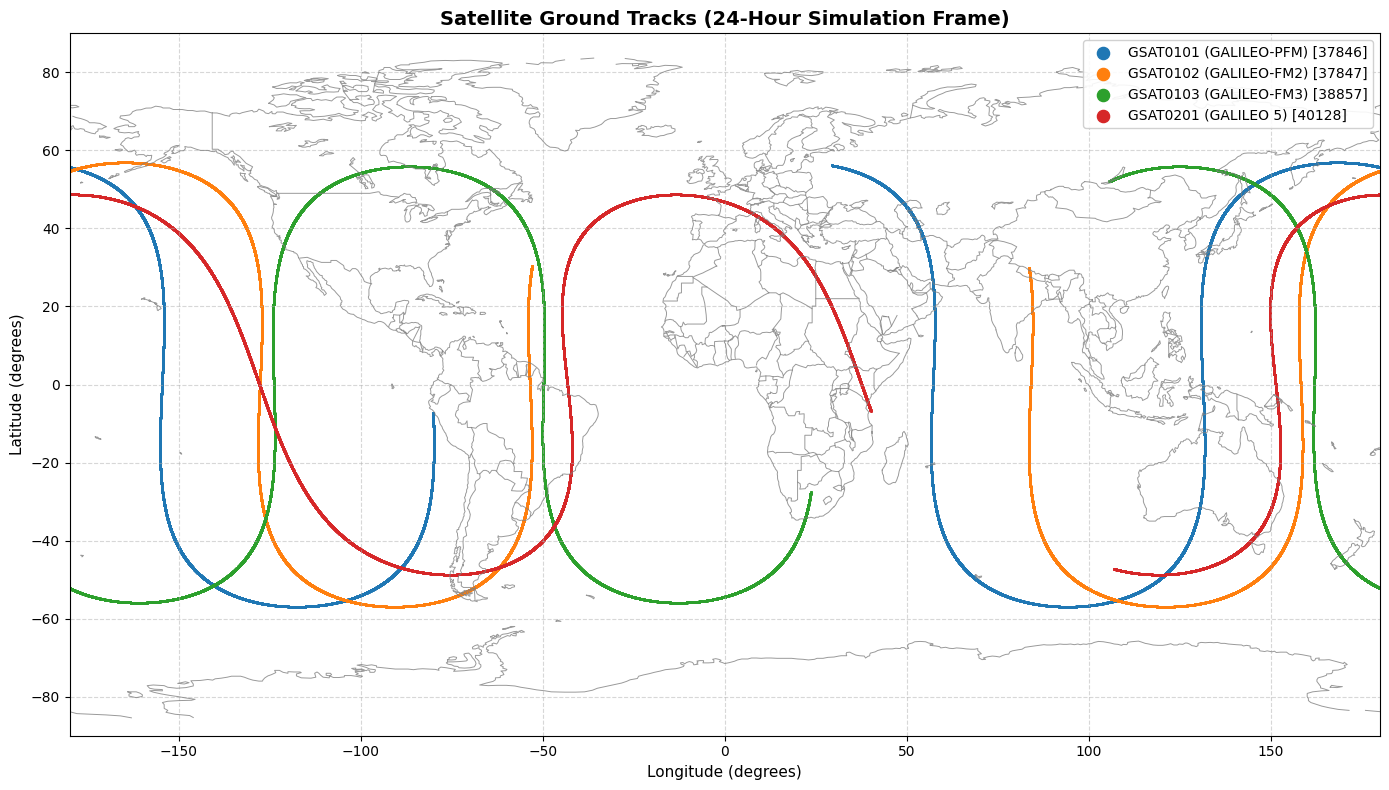

Saved Ground Tracks Plot to: /content/satellite_orbits/output/ground_tracks.png


In [34]:
# --- Figure 1: Ground Tracks Plot ---
plt.figure(figsize=(14, 8))

# 1. Plot the Earth coastline map in gray
coastlines = load_coastline(IN_DIR / 'world_map.txt')
for lons, lats in coastlines:
    plt.plot(lons, lats, color='gray', linewidth=0.7, alpha=0.8)

# 2. Scatter-plot each satellite ground track
for idx, el in enumerate(elements):
    track = tracks[idx]
    lons = [pt['lon_deg'] for pt in track]
    lats = [pt['lat_deg'] for pt in track]

    # Using small scatter dots avoids false connection lines at boundary wraps (-180 to 180)
    plt.scatter(lons, lats, s=1.2, color=COLORS[idx], label=el['label'])

plt.title("Satellite Ground Tracks (24-Hour Simulation Frame)", fontsize=14, fontweight='bold')
plt.xlabel("Longitude (degrees)", fontsize=11)
plt.ylabel("Latitude (degrees)", fontsize=11)
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(markerscale=8, loc='upper right', framealpha=0.9)

plt.tight_layout()
gt_plot_path = OUT_DIR / 'ground_tracks.png'
plt.savefig(gt_plot_path, dpi=200)
plt.show()
print(f"Saved Ground Tracks Plot to: {gt_plot_path}")

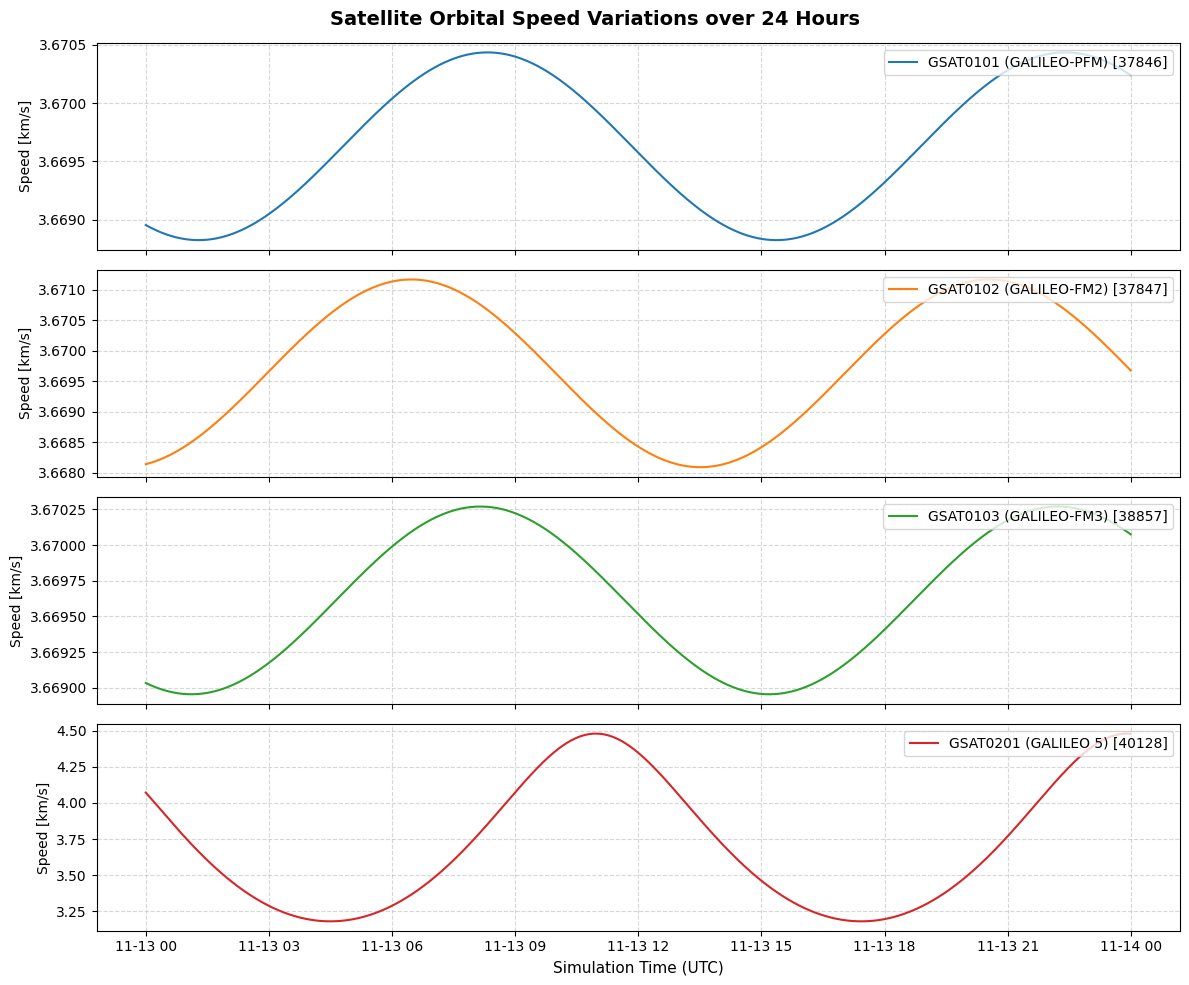

Saved Velocity Timeseries to: /content/satellite_orbits/output/velocity_timeseries.png


In [35]:
# --- Figure 2: Velocity Timeseries ---
fig, axs = plt.subplots(len(elements), 1, figsize=(12, 10), sharex=True)

for idx, el in enumerate(elements):
    track = tracks[idx]
    utc_times = [pt['time'] for pt in track]
    speeds = [pt['speed_km_s'] for pt in track]

    ax = axs[idx]
    ax.plot(utc_times, speeds, color=COLORS[idx], linewidth=1.5, label=el['label'])
    ax.set_ylabel("Speed [km/s]", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.get_yaxis().get_major_formatter().set_useOffset(False)  # Turn off scientific offset display
    ax.legend(loc='upper right')

axs[-1].set_xlabel("Simulation Time (UTC)", fontsize=11)
plt.suptitle("Satellite Orbital Speed Variations over 24 Hours", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()

vel_plot_path = OUT_DIR / 'velocity_timeseries.png'
plt.savefig(vel_plot_path, dpi=200)
plt.show()
print(f"Saved Velocity Timeseries to: {vel_plot_path}")